# E-commerce Customer Purchase Behavior Analysis

## Exploratory Data Analysis

This notebook explores customer purchasing behavior, sales performance, product performance, and geographic patterns using the cleaned e-commerce transaction dataset.

### Analysis Areas
- Data Overview
- Typical Transaction
- Sales Performance
- Customer Purchase Behavior
- Product Performance
- Geographic Analysis
- Key Findings
- Business Recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("cleaned_data.csv")

## 1. Data Overview

The cleaned dataset contains 524,558 transaction records representing 19,865 unique transactions.

There are 4,335 identified customers, while some transaction records do not contain CustomerID. Therefore, customer-level analysis is restricted to records with valid CustomerID, while transaction-level analysis uses the complete cleaned dataset.

In [3]:
df.shape 

(524558, 9)

In [4]:
#untuk mengetahui jumlah transaksi
df["InvoiceNo"].nunique()

19865

In [5]:
df.groupby("InvoiceNo").size().sort_values(ascending=False)

InvoiceNo
573585    1114
581219     749
581492     731
580729     721
558475     705
          ... 
541607       1
565400       1
560275       1
568195       1
554642       1
Length: 19865, dtype: int64

In [6]:
df[df["InvoiceNo"] == 581483][["InvoiceNo", "Description", "Quantity"]]

,InvoiceNo,Description,Quantity
523084,581483,"PAPER CRAFT , LITTLE BIRDIE",80995


In [7]:
df.groupby("CustomerID")["InvoiceNo"].nunique()

CustomerID
12346.0     1
12347.0     7
12348.0     4
12349.0     1
12350.0     1
           ..
18280.0     1
18281.0     1
18282.0     2
18283.0    16
18287.0     3
Name: InvoiceNo, Length: 4335, dtype: int64

In [8]:
df["CustomerID"].nunique()

4335

In [9]:
df["CustomerID"].isnull().sum()


132145

In [10]:
df["StockCode"].nunique()

3918

In [11]:
df["Revenue"].sum()

10539534.834

In [38]:
summary = pd.DataFrame({
    "Metric": [
        "Transaction records",
        "Unique transactions",
        "Identified customers",
        "Unique StockCodes",
        "Unique product descriptions",
        "Countries"
    ],
    "Value": [
        len(df),
        df["InvoiceNo"].nunique(),
        df["CustomerID"].nunique(),
        df["StockCode"].nunique(),
        df["Description"].nunique(),
        df["Country"].nunique()
    ]
})

summary

,Metric,Value
0,Transaction records,524558
1,Unique transactions,19865
2,Identified customers,4335
3,Unique StockCodes,3918
4,Unique product descriptions,4023
5,Countries,38


In [13]:
df[df["InvoiceDate"].dt.year == 2010]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
40952,539991,21618,4 WILDFLOWER BOTANICAL CANDLES,1,2010-12-23 16:49:00,1.25,NaN,United Kingdom,1.25
40953,539991,72741,GRAND CHOCOLATECANDLE,4,2010-12-23 16:49:00,1.45,NaN,United Kingdom,5.80
40954,539992,21470,FLOWER VINE RAFFIA FOOD COVER,1,2010-12-23 17:41:00,3.75,NaN,United Kingdom,3.75
40955,539992,22258,FELT FARM ANIMAL RABBIT,1,2010-12-23 17:41:00,1.25,NaN,United Kingdom,1.25


In [14]:
df["InvoiceDate"].min()

Timestamp('2010-12-01 08:26:00')

In [15]:
df["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

## 2. Typical Transaction

This section examines what a typical transaction looks like by analyzing quantity, revenue, and unit price.

The objective is to understand:
- How many items are typically purchased in a transaction?
- How much revenue does a typical transaction generate?
- Are products generally low-priced or high-priced?

In [39]:
#Quantity per transaction
quantity_per_transaction = (
    df.groupby("InvoiceNo")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

quantity_per_transaction.describe()

count    19865.000000
mean       280.162698
std        956.770839
min          1.000000
25%         70.000000
50%        152.000000
75%        296.000000
max      80995.000000
Name: Quantity, dtype: float64

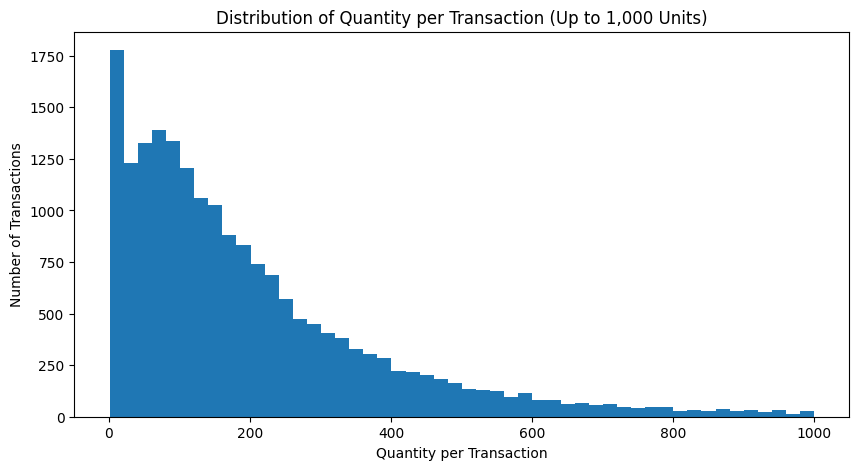

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(
    quantity_per_transaction[quantity_per_transaction <= 1000],
    bins=50
)

plt.title("Distribution of Quantity per Transaction (Up to 1,000 Units)")
plt.xlabel("Quantity per Transaction")
plt.ylabel("Number of Transactions")

plt.show()

Most transactions contain relatively small quantities, while a small number of transactions contain unusually large quantities. The maximum observed quantity in a transaction is **80,995 units**, indicating the presence of extreme transaction-level outliers.

### Revenue per Transaction

Revenue per transaction is examined to understand the typical monetary value of a transaction and identify whether revenue is concentrated among a small number of high-value transactions.

In [42]:
revenue_per_transaction = (
    df.groupby("InvoiceNo")["Revenue"]
    .sum()
)

revenue_per_transaction.describe()

count     19865.000000
mean        530.558008
std        1778.667262
min           0.380000
25%         151.760000
50%         303.200000
75%         491.790000
max      168469.600000
Name: Revenue, dtype: float64

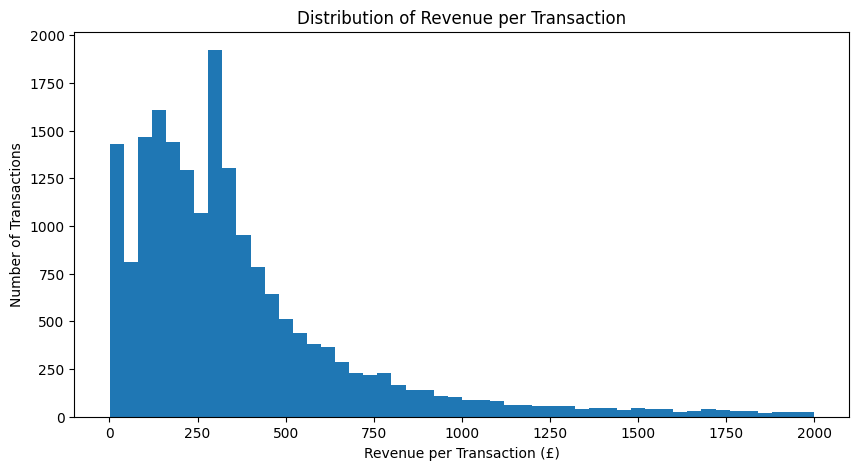

In [43]:
plt.figure(figsize=(10, 5))

plt.hist(
    revenue_per_transaction[revenue_per_transaction <= 2000],
    bins=50
)

plt.title("Distribution of Revenue per Transaction")
plt.xlabel("Revenue per Transaction (£)")
plt.ylabel("Number of Transactions")

plt.show()

Most transactions generate relatively low revenue, while a smaller number of transactions contribute substantially higher revenue. This indicates a right-skewed revenue distribution with a limited number of high-value transactions.

### Unit Price Distribution

UnitPrice is analyzed to understand the typical price level of products and identify whether the distribution is affected by a small number of high-priced items.

In [44]:
df["UnitPrice"].describe()

count    524558.000000
mean          3.736379
std          20.784204
min           0.001000
25%           1.250000
50%           2.080000
75%           4.130000
max        8142.750000
Name: UnitPrice, dtype: float64

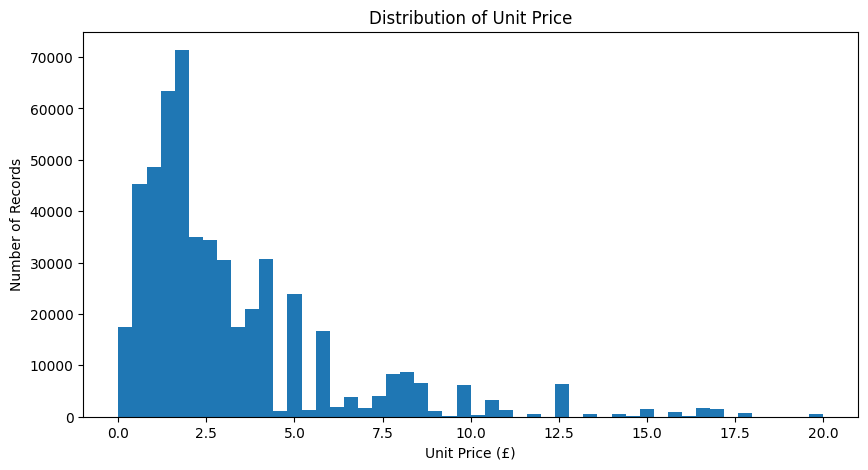

In [45]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["UnitPrice"][df["UnitPrice"] <= 20],
    bins=50
)

plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price (£)")
plt.ylabel("Number of Records")

plt.show()

The UnitPrice distribution is strongly right-skewed. The median UnitPrice is approximately **£2.08**, indicating that most products are relatively low-priced, while a smaller number of higher-priced items increase the upper tail of the distribution.

In [16]:
df["Country"].value_counts()

Country
United Kingdom          479707
Germany                   9017
France                    8387
EIRE                      7874
Spain                     2479
Netherlands               2359
Belgium                   2031
Switzerland               1958
Portugal                  1485
Australia                 1181
Norway                    1068
Italy                      758
Channel Islands            746
Finland                    684
Cyprus                     602
Sweden                     449
Unspecified                442
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     292
Hong Kong                  277
Singapore                  215
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         57


### Revenue by Country

Revenue is analyzed across countries to identify the markets that contribute the most to overall sales.

This analysis helps identify the geographic markets with the largest revenue contribution.

In [17]:
df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)

Country
United Kingdom          8941988.244
Netherlands              285446.340
EIRE                     276090.860
Germany                  226382.150
France                   200133.000
Australia                138453.810
Spain                     61558.560
Switzerland               57067.600
Belgium                   41196.340
Sweden                    38337.830
Japan                     37416.370
Norway                    35325.140
Portugal                  29459.110
Finland                   21994.880
Channel Islands           20147.540
Denmark                   18955.340
Italy                     17483.240
Cyprus                    13182.160
Austria                   10198.680
Hong Kong                  9919.190
Singapore                  9120.390
Israel                     8129.410
Poland                     7334.650
Greece                     4760.520
Unspecified                4740.940
Iceland                    4310.000
Canada                     3666.380
USA                 

### Monthly Revenue Trend

Monthly revenue is analyzed to identify changes in sales performance over time.

The analysis helps identify high-performing and low-performing months and provides an overview of seasonal patterns in revenue.

In [18]:
monthly_revenue = (df.groupby(df['InvoiceDate'].dt.to_period("M"))["Revenue"].sum())

In [19]:
#mencari tau highest nya dibulan apa 
monthly_revenue.sort_values(ascending=False)

InvoiceDate
2011-11    1500554.360
2011-10    1130075.060
2011-09    1050350.002
2010-12     805431.140
2011-05     764075.380
2011-06     755619.130
2011-08     743467.280
2011-03     707759.120
2011-07     706968.321
2011-01     689714.710
2011-12     637352.230
2011-04     526859.991
2011-02     521308.110
Freq: M, Name: Revenue, dtype: float64

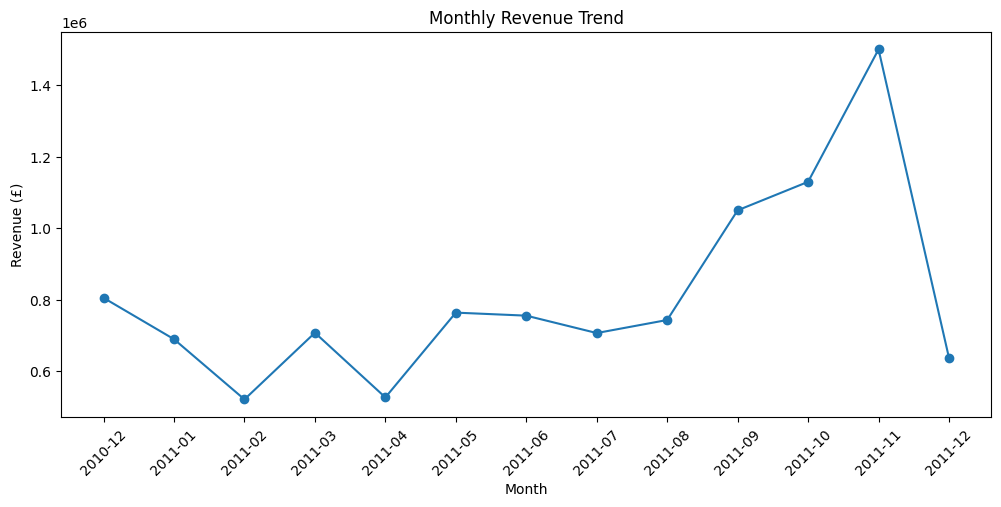

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.show()

Revenue remained relatively stable during the earlier months before increasing substantially from September onward. Revenue reached its highest level in **November 2011 at approximately £1.50 million**, while **February 2011** recorded the lowest revenue at approximately **£521,308**.

### Monthly Transaction Volume

The number of unique transactions is analyzed on a monthly basis to understand changes in purchasing activity over time.

Comparing transaction volume with revenue can help determine whether changes in sales are driven by the number of transactions.

In [20]:
#seperti pivot di excel 
monthly_transaction = (
    df.groupby(df['InvoiceDate'].dt.to_period("M"))["InvoiceNo"].nunique()
)

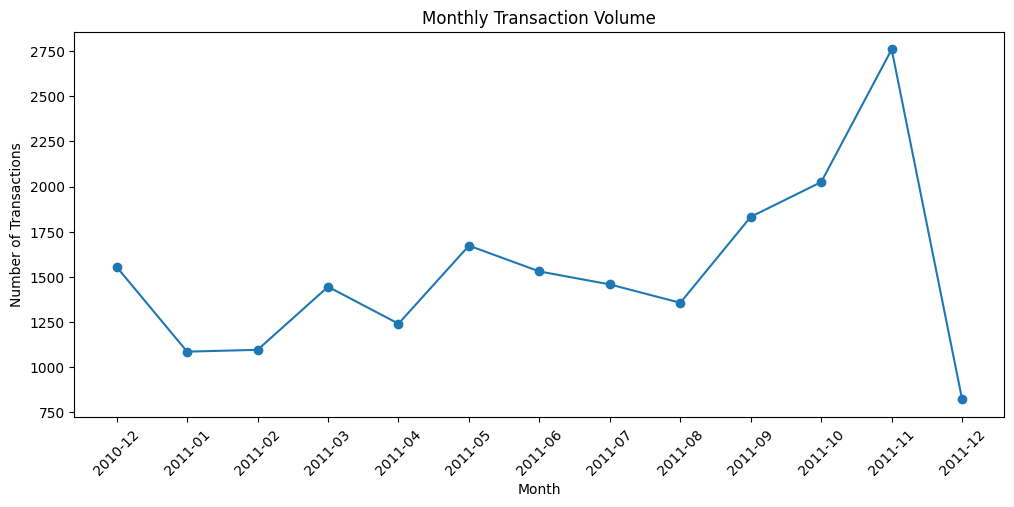

In [47]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_transaction.index.astype(str),
    monthly_transaction.values,
    marker="o"
)

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.show()

Transaction volume follows a similar pattern to revenue, reaching its highest level in **November 2011 with 2,761 transactions**. The simultaneous increase in revenue and transaction volume suggests that the late-year revenue increase was primarily driven by higher purchasing activity.

### Average Order Value (AOV)

Average Order Value (AOV) is calculated by dividing total monthly revenue by the number of unique transactions.

AOV is used to understand the average value generated by each transaction and to complement the analysis of transaction volume and revenue.

In [21]:
#menghitung AOV 
monthly = df.groupby(df["InvoiceDate"].dt.to_period("M")).agg({
    "Revenue":"sum",
    "InvoiceNo":"nunique"
})

monthly["AOV"] = monthly["Revenue"] / monthly["InvoiceNo"]

monthly

,Revenue,InvoiceNo,AOV
InvoiceDate,,,
2010-12,805431.140,1554,518.295457
2011-01,689714.710,1084,636.268183
2011-02,521308.110,1094,476.515640
2011-03,707759.120,1444,490.137895
2011-04,526859.991,1239,425.230017
2011-05,764075.380,1672,456.982883
2011-06,755619.130,1529,494.191714
2011-07,706968.321,1457,485.221909
2011-08,743467.280,1355,548.684339


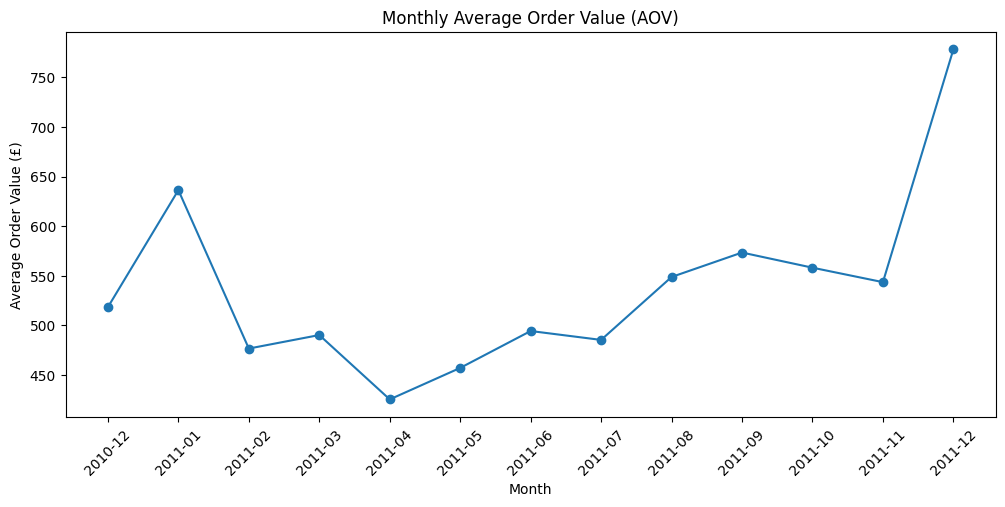

In [48]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly.index.astype(str),
    monthly["AOV"],
    marker="o"
)

plt.title("Monthly Average Order Value (AOV)")
plt.xlabel("Month")
plt.ylabel("Average Order Value (£)")
plt.xticks(rotation=45)

plt.show()

Monthly AOV fluctuates across the period rather than showing the same upward trend as transaction volume. The highest AOV occurs in **December 2011 (£778.21)**, while the lowest occurs in **April 2011 (£425.23)**.

December should be interpreted cautiously because the dataset only covers transactions up to **9 December 2011**.

## 3. Customer Analysis

This section examines customer purchasing behavior to understand customer activity, spending patterns, and purchase frequency.

The analysis focuses on identifying high-value customers and understanding the distribution of customer contributions to total revenue.

In [23]:
#customer yang aktif di dataset, hanya transaksi yang memiliki customerID
customer_df = df[df["CustomerID"].notna()].copy()
customer_df["CustomerID"].nunique()

4335

In [24]:
total_revenue = df["Revenue"].sum()

### Top 10 Customers by Spending

The top 10 customers are identified based on their total spending.

Their contribution to total revenue is then calculated to determine whether the business is highly dependent on a small group of customers.

In [49]:
#top 10 customer by their spending 
top10_customers = (
    customer_df.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top10_customers

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    140336.83
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

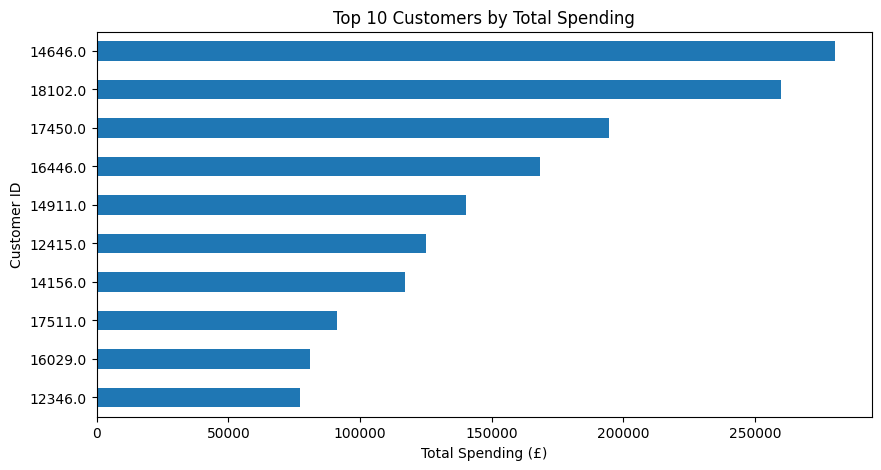

In [50]:
plt.figure(figsize=(10, 5))

top10_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending (£)")
plt.ylabel("Customer ID")

plt.show()

The top 10 customers contribute approximately **14.56% of total revenue**, indicating that revenue is relatively distributed across the customer base rather than being highly concentrated among a small number of customers.

### Average Customer Spending

Average customer spending is calculated across identified customers to estimate the typical revenue contribution per customer.

In [26]:
customer = (
    customer_df.groupby("CustomerID")["Revenue"].sum()
)

customer.mean()

2037.7829213379473

In [27]:
#check insight apakah revenue tertinggi kita ada dari top 10 ini?
(top10_customer_by_spending/total_revenue)*100

14.557424916424925

### Purchase Frequency

Purchase frequency is measured using the number of unique transactions associated with each customer.

This analysis helps identify customers who make purchases more frequently and can provide an indication of customer engagement.

In [28]:
purchase_frequency = (
    customer_df.groupby("CustomerID")["InvoiceNo"].nunique().sort_values(ascending=False)
)

purchase_frequency.head(10)

CustomerID
12748.0    206
14911.0    199
17841.0    124
13089.0     97
14606.0     92
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

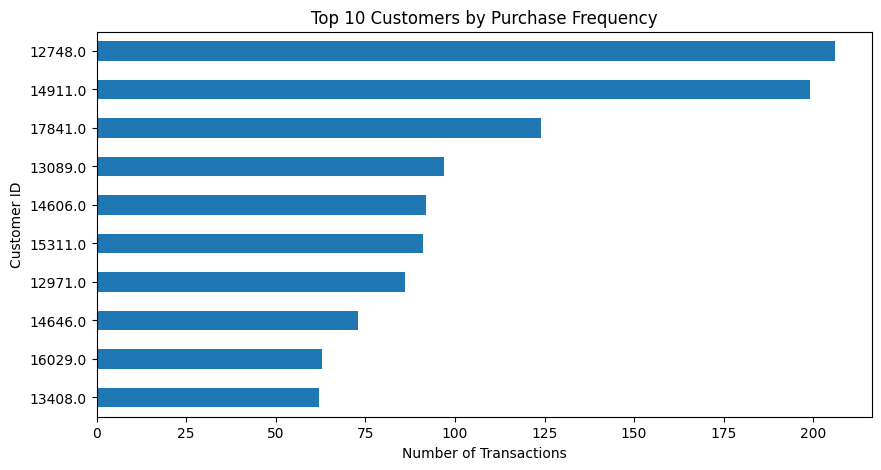

In [51]:
top10_frequency = purchase_frequency.head(10).sort_values()

plt.figure(figsize=(10, 5))

top10_frequency.plot(kind="barh")

plt.title("Top 10 Customers by Purchase Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Customer ID")

plt.show()

Customer **12748** has the highest purchase frequency with **206 unique transactions**. However, purchase frequency does not necessarily correspond to the highest total spending, indicating that customer loyalty and monetary value should be evaluated separately.

## 4. Product Analysis

This section analyzes product performance based on revenue and quantity sold.

The objective is to identify products that generate the most revenue and products with the highest sales volume.

In [29]:
# Create a physical_products dataset that does not contain items that are not physical products.
physical_products = df[
    ~df["Description"].str.upper().isin([
        "DOTCOM POSTAGE",
        "POSTAGE"
    ])
].copy()

### Top Products by Revenue

Products are ranked based on their total revenue contribution.

This analysis identifies products that generate the highest sales value and can help highlight important products from a revenue perspective.

In [30]:
top_revenue_product = (
    physical_products.groupby("Description")["Revenue"].sum().sort_values(ascending=False)
)

top_revenue_product.head(10)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64

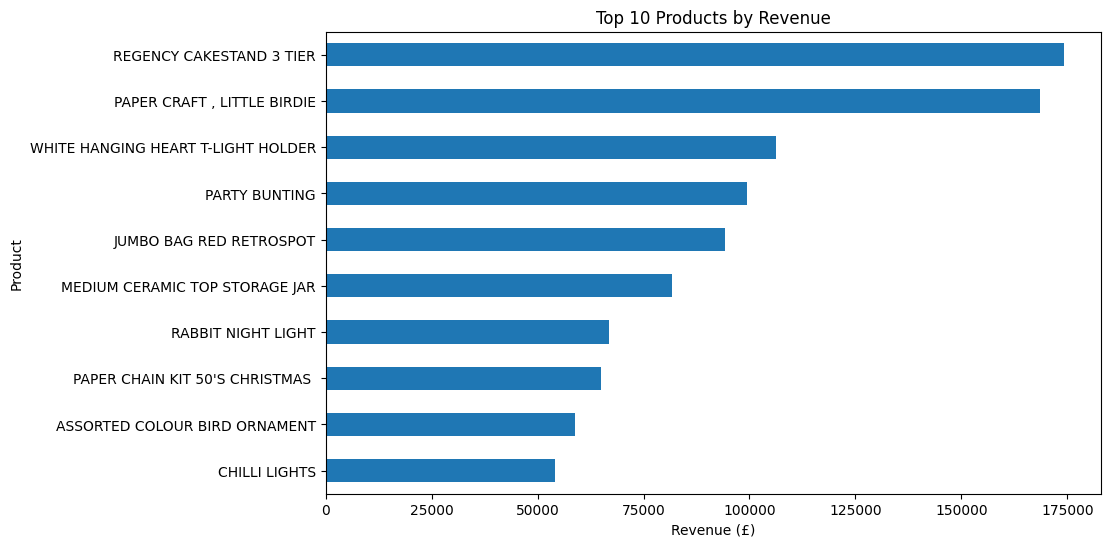

In [52]:
top10_revenue_products = top_revenue_product.head(10).sort_values()

plt.figure(figsize=(10, 6))

top10_revenue_products.plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.show()

**REGENCY CAKESTAND 3 TIER** generates the highest revenue among physical products, contributing approximately **£174,156.54**.

### Top Products by Quantity Sold

Products are ranked based on their total quantity sold.

Comparing quantity sold with revenue helps distinguish high-volume products from high-value products.

In [31]:
top_quantity_products = (
    physical_products.groupby("Description")["Quantity"].sum().sort_values(ascending=False)
)

top_quantity_products.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

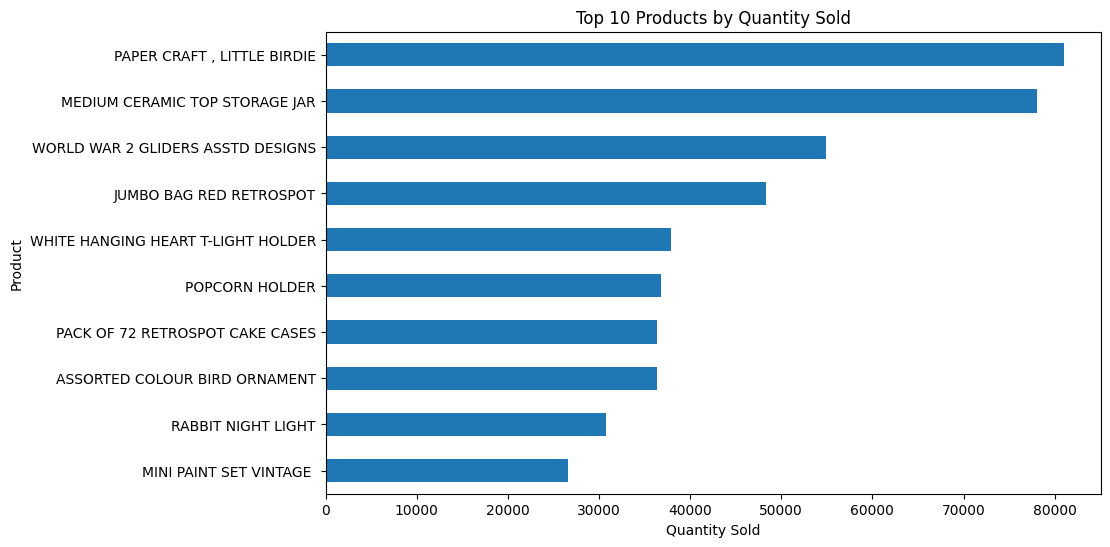

In [53]:
top10_quantity_products = top_quantity_products.head(10).sort_values()

plt.figure(figsize=(10, 6))

top10_quantity_products.plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.show()

**PAPER CRAFT, LITTLE BIRDIE** has the highest sales quantity at **80,995 units**.

### Top Product Overlap

The top 10 products by quantity are compared with the top 10 products by revenue to determine whether high sales volume also translates into strong revenue contribution.

In [54]:
top10_revenue_set = set(top_revenue_product.head(10).index)
top10_quantity_set = set(top_quantity_products.head(10).index)

overlap = top10_revenue_set.intersection(top10_quantity_set)

print("Number of overlapping products:", len(overlap))
print("Overlap percentage:", len(overlap) / 10 * 100, "%")

Number of overlapping products: 6
Overlap percentage: 60.0 %


**6 out of 10 products (60%)** appear in both the top 10 revenue and top 10 quantity rankings. This indicates that several high-demand products also make strong contributions to revenue, although sales volume alone does not determine revenue performance.

## 5. Geographic Analysis

This section examines sales and customer distribution across different countries.

The analysis focuses on revenue contribution, transaction volume, customer count, and average customer spending by country.

### Revenue by Country

Revenue is aggregated by country to identify the markets contributing the most to total sales.

In [32]:
top_10_country = (
    df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
)

top_10_country.head(10)

Country
United Kingdom    8941988.244
Netherlands        285446.340
EIRE               276090.860
Germany            226382.150
France             200133.000
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38337.830
Name: Revenue, dtype: float64

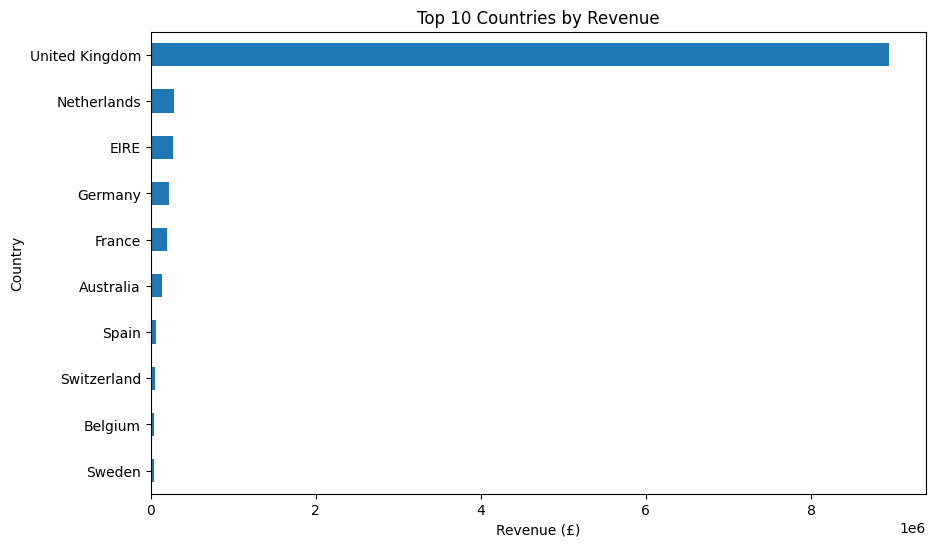

In [55]:
top10_country_revenue = top_10_country.head(10).sort_values()

plt.figure(figsize=(10, 6))

top10_country_revenue.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.show()

The **United Kingdom** generates the highest revenue at approximately **£8.94 million**, making it the company's largest market by revenue.

### Transactions by Country

The number of unique transactions is compared across countries to identify markets with the highest purchasing activity.

In [56]:
#mengetahui transaction tertinggi
transactions_by_country = (
    df.groupby("Country")["InvoiceNo"]
      .nunique()
      .sort_values(ascending=False)
)

transactions_by_country

Country
United Kingdom          17954
Germany                   451
France                    388
EIRE                      284
Belgium                    98
Netherlands                94
Spain                      90
Australia                  57
Switzerland                54
Portugal                   52
Finland                    40
Italy                      38
Sweden                     36
Norway                     35
Channel Islands            25
Japan                      19
Poland                     19
Denmark                    18
Austria                    17
Cyprus                     15
Unspecified                13
Israel                      8
Hong Kong                   8
Iceland                     7
Canada                      6
USA                         5
Malta                       5
Greece                      5
European Community          4
Lithuania                   4
Singapore                   4
Bahrain                     3
United Arab Emirates        3
Cz

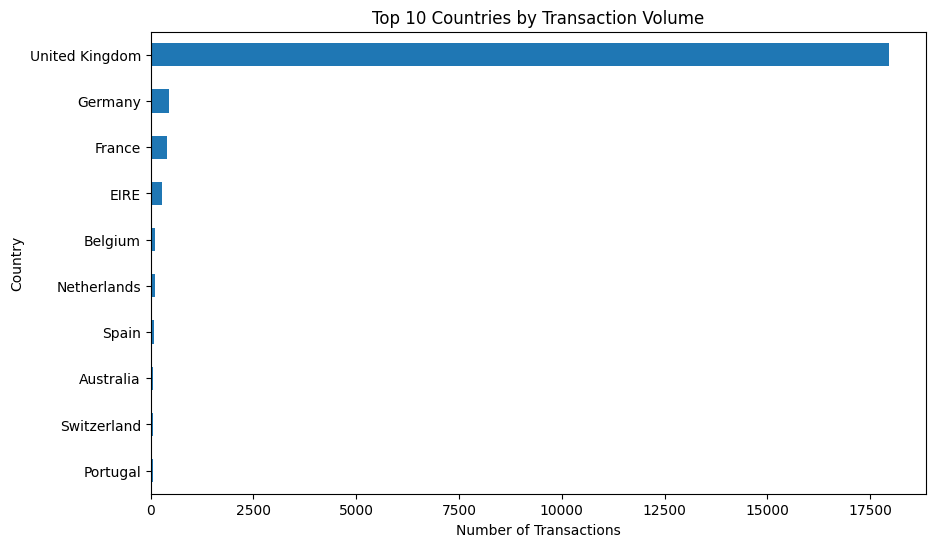

In [57]:
top10_country_transactions = transactions_by_country.head(10).sort_values()

plt.figure(figsize=(10, 6))

top10_country_transactions.plot(kind="barh")

plt.title("Top 10 Countries by Transaction Volume")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")

plt.show()

The **United Kingdom** also records the highest transaction volume, with **17,954 unique transactions**.

### Customer Count by Country

In [33]:
top_10_country_byCustomer = (
    df.groupby("Country")["CustomerID"].nunique().sort_values(ascending=False)
)

top_10_country_byCustomer.head(10)

Country
United Kingdom    3917
Germany             94
France              87
Spain               30
Belgium             25
Switzerland         21
Portugal            19
Italy               14
Finland             12
Austria             11
Name: CustomerID, dtype: int64

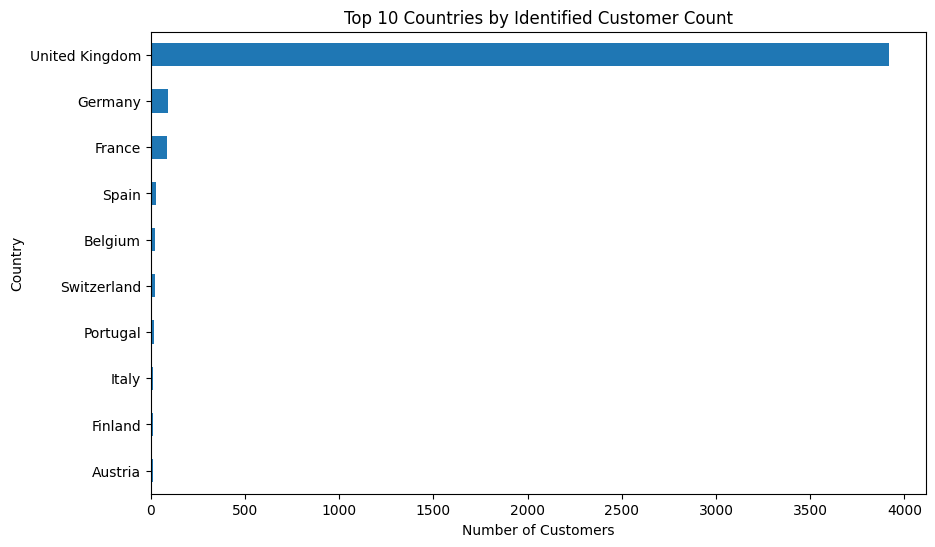

In [58]:
top10_country_customers = top_10_country_byCustomer.head(10).sort_values()

plt.figure(figsize=(10, 6))

top10_country_customers.plot(kind="barh")

plt.title("Top 10 Countries by Identified Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("Country")

plt.show()

The **United Kingdom** has the largest identified customer base, with **3,917 customers**.

### Average Customer Spending by Country

Average customer spending is calculated by dividing total revenue by the number of unique customers in each country.

This analysis helps identify markets where customers generate relatively high spending on average.

In [37]:
# Average customer spending by country
# Only records with identified CustomerID are included

customer_df = df[df["CustomerID"].notna()].copy()

country_avg = (
    customer_df.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Customer=("CustomerID", "nunique")
    )
)

country_avg["Average Spending"] = (
    country_avg["Revenue"] / country_avg["Customer"]
)

country_avg = (
    country_avg[country_avg["Customer"] > 0]
    .sort_values("Average Spending", ascending=False)
)

country_avg

,Revenue,Customer,Average Spending
Country,,,
EIRE,261888.120,3,87296.040000
Netherlands,285446.340,9,31716.260000
Australia,138453.810,9,15383.756667
Singapore,9120.390,1,9120.390000
Sweden,38337.830,8,4792.228750
Japan,37416.370,8,4677.046250
Iceland,4310.000,1,4310.000000
Norway,35325.140,10,3532.514000
Switzerland,56443.950,21,2687.807143


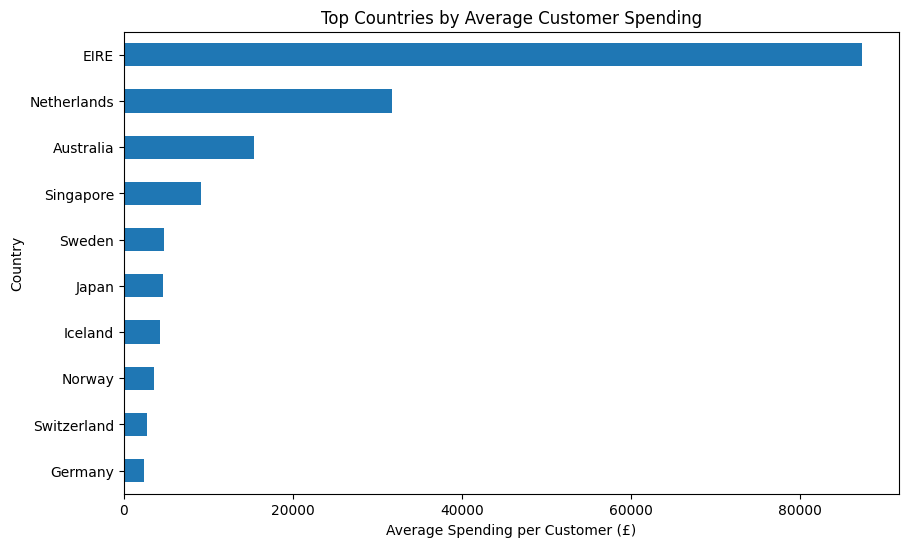

In [59]:
top10_country_avg = country_avg["Average Spending"].head(10).sort_values()

plt.figure(figsize=(10, 6))

top10_country_avg.plot(kind="barh")

plt.title("Top Countries by Average Customer Spending")
plt.xlabel("Average Spending per Customer (£)")
plt.ylabel("Country")

plt.show()

**EIRE** has the highest average spending per identified customer at **£87,296.04**, followed by the Netherlands (£31,716.26) and Australia (£15,383.76).

However, EIRE's result is based on only **3 identified customers**, so the figure should be interpreted cautiously.

## 6. Key Findings

### 1. Business Scale
The cleaned dataset contains **524,558 transaction records**, representing **19,865 unique transactions**, **4,335 identified customers**, **3,918 unique StockCodes**, **4,023 unique product descriptions**, and **38 countries**.

### 2. Sales Trend
Revenue and transaction volume increase substantially toward the end of the year, with **November 2011** reaching the highest revenue (**£1.50 million**) and transaction volume (**2,761 transactions**).

### 3. Customer Behavior
The top 10 customers contribute approximately **14.56% of total revenue**, indicating that revenue is relatively distributed across the customer base rather than being highly concentrated among a small group of customers.

### 4. Customer Loyalty
Customer **12748** has the highest purchase frequency with **206 unique transactions**. However, purchase frequency does not necessarily correspond to the highest total spending.

### 5. Product Performance
**6 out of 10 products (60%)** appear in both the top 10 revenue and top 10 quantity rankings. This indicates that several high-demand products also make strong contributions to revenue, although sales volume alone does not determine revenue performance.

### 6. Geographic Performance
The **United Kingdom** is the largest market by revenue, transaction volume, and identified customer base. Meanwhile, **EIRE** has the highest average spending per identified customer at **£87,296.04**, based on only three identified customers.

## 8. Business Recommendations

### 1. Customer Strategy

Maintain a broad customer acquisition and retention strategy rather than relying heavily on a small group of high-value customers. Frequently purchasing customers should also be targeted with loyalty initiatives to encourage repeat purchases and increase long-term customer value.

### 2. Product Strategy

Prioritize inventory availability and promotional activities for products that perform strongly in both sales quantity and revenue. Product performance should be evaluated using both metrics rather than either one alone.

### 3. Geographic Strategy

Maintain customer retention and market coverage in the UK, which represents the company's largest market. EIRE could be explored for higher-value customer opportunities, but further customer data should be collected before making major strategic decisions because the current average is based on only three identified customers.

### 4. Seasonal Strategy

Increase inventory readiness and promotional planning ahead of the September–November period to prepare for higher transaction volume. The observed seasonal pattern should be monitored across additional periods before being treated as a recurring trend.